### Trains an agent with (stochastic) Policy Gradients on Pong. Uses OpenAI Gym.

In [ ]:
# !pip install gymnasium[atari]
!pip install gymnasium[atari] ale-py

In [ ]:
import numpy as np
import pickle
import gymnasium as gym

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
# # hyperparameters
# H = 200 # number of hidden layer neurons
# batch_size = 10 # every how many episodes to do a param update?
# learning_rate = 1e-4
# gamma = 0.99 # discount factor for reward
# decay_rate = 0.99 # decay factor for RMSProp leaky sum of grad^2
# resume = False # resume from previous checkpoint?
# render = False

# # model initialization
# D = 80 * 80 # input dimensionality: 80x80 grid
# if resume:
#   model = pickle.load(open('save.p', 'rb'))
# else:
#   model = {}
#   model['W1'] = np.random.randn(H,D) / np.sqrt(D) # "Xavier" initialization
#   model['W2'] = np.random.randn(H) / np.sqrt(H)

# grad_buffer = { k : np.zeros_like(v) for k,v in model.iteritems() } # update buffers that add up gradients over a batch
# rmsprop_cache = { k : np.zeros_like(v) for k,v in model.iteritems() } # rmsprop memory

# def sigmoid(x):
#   return 1.0 / (1.0 + np.exp(-x)) # sigmoid "squashing" function to interval [0,1]

# def prepro(I):
#   """ prepro 210x160x3 uint8 frame into 6400 (80x80) 1D float vector """
#   I = I[35:195] # crop
#   I = I[::2,::2,0] # downsample by factor of 2
#   I[I == 144] = 0 # erase background (background type 1)
#   I[I == 109] = 0 # erase background (background type 2)
#   I[I != 0] = 1 # everything else (paddles, ball) just set to 1
#   return I.astype(np.float).ravel()

# def discount_rewards(r):
#   """ take 1D float array of rewards and compute discounted reward """
#   discounted_r = np.zeros_like(r)
#   running_add = 0
#   for t in reversed(xrange(0, r.size)):
#     if r[t] != 0: running_add = 0 # reset the sum, since this was a game boundary (pong specific!)
#     running_add = running_add * gamma + r[t]
#     discounted_r[t] = running_add
#   return discounted_r

# def policy_forward(x):
#   h = np.dot(model['W1'], x)
#   h[h<0] = 0 # ReLU nonlinearity
#   logp = np.dot(model['W2'], h)
#   p = sigmoid(logp)
#   return p, h # return probability of taking action 2, and hidden state

# def policy_backward(eph, epdlogp):
#   """ backward pass. (eph is array of intermediate hidden states) """
#   dW2 = np.dot(eph.T, epdlogp).ravel()
#   dh = np.outer(epdlogp, model['W2'])
#   dh[eph <= 0] = 0 # backpro prelu
#   dW1 = np.dot(dh.T, epx)
#   return {'W1':dW1, 'W2':dW2}

# env = gym.make("Pong-v0")
# observation = env.reset()
# prev_x = None # used in computing the difference frame
# xs,hs,dlogps,drs = [],[],[],[]
# running_reward = None
# reward_sum = 0
# episode_number = 0
# while True:
#   if render: env.render()

#   # preprocess the observation, set input to network to be difference image
#   cur_x = prepro(observation)
#   x = cur_x - prev_x if prev_x is not None else np.zeros(D)
#   prev_x = cur_x

#   # forward the policy network and sample an action from the returned probability
#   aprob, h = policy_forward(x)
#   action = 2 if np.random.uniform() < aprob else 3 # roll the dice!

#   # record various intermediates (needed later for backprop)
#   xs.append(x) # observation
#   hs.append(h) # hidden state
#   y = 1 if action == 2 else 0 # a "fake label"
#   dlogps.append(y - aprob) # grad that encourages the action that was taken to be taken (see http://cs231n.github.io/neural-networks-2/#losses if confused)

#   # step the environment and get new measurements
#   observation, reward, done, info = env.step(action)
#   reward_sum += reward

#   drs.append(reward) # record reward (has to be done after we call step() to get reward for previous action)

#   if done: # an episode finished
#     episode_number += 1

#     # stack together all inputs, hidden states, action gradients, and rewards for this episode
#     epx = np.vstack(xs)
#     eph = np.vstack(hs)
#     epdlogp = np.vstack(dlogps)
#     epr = np.vstack(drs)
#     xs,hs,dlogps,drs = [],[],[],[] # reset array memory

#     # compute the discounted reward backwards through time
#     discounted_epr = discount_rewards(epr)
#     # standardize the rewards to be unit normal (helps control the gradient estimator variance)
#     discounted_epr -= np.mean(discounted_epr)
#     discounted_epr /= np.std(discounted_epr)

#     epdlogp *= discounted_epr # modulate the gradient with advantage (PG magic happens right here.)
#     grad = policy_backward(eph, epdlogp)
#     for k in model: grad_buffer[k] += grad[k] # accumulate grad over batch

#     # perform rmsprop parameter update every batch_size episodes
#     if episode_number % batch_size == 0:
#       for k,v in model.iteritems():
#         g = grad_buffer[k] # gradient
#         rmsprop_cache[k] = decay_rate * rmsprop_cache[k] + (1 - decay_rate) * g**2
#         model[k] += learning_rate * g / (np.sqrt(rmsprop_cache[k]) + 1e-5)
#         grad_buffer[k] = np.zeros_like(v) # reset batch gradient buffer

#     # boring book-keeping
#     running_reward = reward_sum if running_reward is None else running_reward * 0.99 + reward_sum * 0.01
#     print('Resetting env. Episode reward total was %.2f. Running mean: %.2f' % (reward_sum, running_reward))
#     if episode_number % 100 == 0: pickle.dump(model, open('save.p', 'wb'))
#     reward_sum = 0
#     observation = env.reset() # reset env
#     prev_x = None

#   if reward != 0: # Pong has either +1 or -1 reward exactly when game ends.
#     print ('ep %d: game finished, reward: %f' % (episode_number, reward)) + ('' if reward == -1 else ' !!!!!!!!')

AttributeError: 'dict' object has no attribute 'iteritems'

In [ ]:
# import gymnasium as gym
# import ale_py  # Required for Atari environments
# import numpy as np

# # Register Atari environments (optional but helpful for IDEs)
# gym.register_envs(ale_py)

# # Create the Pong environment with human rendering
# env = gym.make("ALE/Pong-v5")

# # Initialize the environment
# obs, info = env.reset()  # Updated reset method

# # Replay buffer for storing experiences
# replay_buffer = []

# # Simulation parameters
# total_timesteps = 1000

# # Main loop
# for _ in range(total_timesteps):
#     action = env.action_space.sample()  # Random action
#     next_obs, reward, terminated, truncated, info = env.step(action)  # Updated step method

#     # Append the experience to the replay buffer
#     replay_buffer.append((obs, action, reward, terminated, truncated, next_obs))

#     # Render the environment (human mode shows visual output)
#     env.render()

#     # Update the observation
#     obs = next_obs

#     # Check termination or truncation
#     if terminated or truncated:
#         obs, info = env.reset()  # Reset environment if episode ends

# # Close the environment
# env.close()


array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [109, 118,  43],
        [109, 118,  43],
        [109, 118,  43]],

       [[109, 118,  43],
        [109, 118,  43],
        [109, 118,  43],
        ...,
        [109, 118,  43],
        [109, 118,  43],
        [109, 118,  43]],

       [[109, 118,  43],
        [109, 118,  43],
        [109, 118,  43],
        ...,
        [109, 118,  43],
        [109, 118,  43],
        [109, 118,  43]],

       ...,

       [[ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24],
        ...,
        [ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24]],

       [[ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24],
        ...,
        [ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24]],

       [[ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24],
        ...,
        [ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24]]], dtype=uint8)
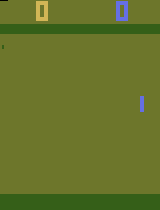

In [ ]:
import gymnasium as gym
from gymnasium.wrappers import PassiveEnvChecker, OrderEnforcing

# Create an environment with strict order enforcing and API validation
env = gym.make("ale_py:ALE/Pong-v5", render_mode="rgb_array")
env = PassiveEnvChecker(env)
env = OrderEnforcing(env, disable_render_order_enforcing=False)

# Reset and render environment
obs, info = env.reset()
env.render()


/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


array([[[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [109, 118,  43],
        [109, 118,  43],
        [109, 118,  43]],

       [[109, 118,  43],
        [109, 118,  43],
        [109, 118,  43],
        ...,
        [109, 118,  43],
        [109, 118,  43],
        [109, 118,  43]],

       [[109, 118,  43],
        [109, 118,  43],
        [109, 118,  43],
        ...,
        [109, 118,  43],
        [109, 118,  43],
        [109, 118,  43]],

       ...,

       [[ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24],
        ...,
        [ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24]],

       [[ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24],
        ...,
        [ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24]],

       [[ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24],
        ...,
        [ 53,  95,  24],
        [ 53,  95,  24],
        [ 53,  95,  24]]], dtype=uint8)
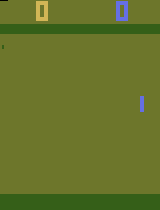

In [ ]:
import gymnasium as gym
from gymnasium.wrappers import PassiveEnvChecker, OrderEnforcing

# Create an environment with strict order enforcing and API validation
env = gym.make("ale_py:ALE/Pong-v5", render_mode="rgb_array", obs_type="grayscale", disable_env_checker=False)
env = PassiveEnvChecker(env)
env = OrderEnforcing(env, disable_render_order_enforcing=True)
obs, info = env.reset()
env.render()
# env.close()

In [ ]:
# import gymnasium as gym
# from gymnasium.wrappers import PassiveEnvChecker, OrderEnforcing

# # Hyperparameters
# H = 200  # Number of hidden layer neurons
# batch_size = 10  # Number of episodes before parameter update
# learning_rate = 1e-4
# gamma = 0.99  # Discount factor for reward
# decay_rate = 0.99  # RMSProp decay factor
# resume = False  # Resume from previous checkpoint
# render = False  # Render the environment

# # Model initialization
# D = 80 * 80  # Input dimensionality: 80x80 grid
# if resume:
#     with open('save.p', 'rb') as f:
#         model = pickle.load(f)
# else:
#     model = {
#         'W1': np.random.randn(H, D) / np.sqrt(D),  # Xavier initialization
#         'W2': np.random.randn(H) / np.sqrt(H)
#     }

# grad_buffer = {k: np.zeros_like(v) for k, v in model.items()}  # Gradient accumulators
# rmsprop_cache = {k: np.zeros_like(v) for k, v in model.items()}  # RMSProp cache

# # Functions
# def sigmoid(x):
#     return 1.0 / (1.0 + np.exp(-x))  # Sigmoid function

# def prepro(I):
#     """Preprocess 210x160x3 uint8 frame into 6400 (80x80) 1D float vector"""
#     I = I[35:195]  # Crop
#     I = I[::2, ::2, 0]  # Downsample by factor of 2
#     I[(I == 144) | (I == 109)] = 0  # Erase background
#     I[I != 0] = 1  # Set paddles and ball to 1
#     return I.astype(np.float32).ravel()

# def discount_rewards(r):
#     """Compute discounted rewards"""
#     discounted_r = np.zeros_like(r)
#     running_add = 0
#     for t in reversed(range(r.size)):
#         if r[t] != 0:
#             running_add = 0  # Reset at game boundary
#         running_add = running_add * gamma + r[t]
#         discounted_r[t] = running_add
#     return discounted_r

# def policy_forward(x):
#     h = np.dot(model['W1'], x)
#     h[h < 0] = 0  # ReLU activation
#     logp = np.dot(model['W2'], h)
#     p = sigmoid(logp)
#     return p, h  # Probability of action 2, hidden state

# def policy_backward(eph, epdlogp, epx):
#     """Backward pass"""
#     dW2 = np.dot(eph.T, epdlogp).ravel()
#     dh = np.outer(epdlogp, model['W2'])
#     dh[eph <= 0] = 0  # Backprop ReLU
#     dW1 = np.dot(dh.T, epx)
#     return {'W1': dW1, 'W2': dW2}

# # Main program
# env = gym.make("ale_py:ALE/Pong-v5", render_mode="rgb_array")
# env = PassiveEnvChecker(env)  # Add PassiveEnvChecker wrapper
# env = OrderEnforcing(env, disable_render_order_enforcing=False)  # Add OrderEnforcing wrapper

# observation, info = env.reset()
# prev_x = None  # For difference frame
# xs, hs, dlogps, drs = [], [], [], []
# running_reward = None
# reward_sum = 0
# episode_number = 0

# while True:
#     if render:
#         env.render()

#     # Preprocess observation
#     cur_x = prepro(observation)
#     x = cur_x - prev_x if prev_x is not None else np.zeros(D)
#     prev_x = cur_x

#     # Forward pass and action selection
#     aprob, h = policy_forward(x)
#     action = 2 if np.random.uniform() < aprob else 3

#     # Record intermediates
#     xs.append(x)  # Observations
#     hs.append(h)  # Hidden states
#     y = 1 if action == 2 else 0  # Fake label
#     dlogps.append(y - aprob)  # Policy gradient

#     # Step environment
#     observation, reward, terminated, truncated, info = env.step(action)
#     reward_sum += reward
#     drs.append(reward)  # Rewards

#     if terminated or truncated:
#         episode_number += 1

#         # Stack episode data
#         epx = np.vstack(xs)
#         eph = np.vstack(hs)
#         epdlogp = np.vstack(dlogps)
#         epr = np.vstack(drs)
#         xs, hs, dlogps, drs = [], [], [], []  # Reset episode memory

#         # Compute discounted rewards
#         discounted_epr = discount_rewards(epr)
#         discounted_epr -= np.mean(discounted_epr)
#         discounted_epr /= np.std(discounted_epr)

#         # Modulate gradients with advantage
#         epdlogp *= discounted_epr
#         grad = policy_backward(eph, epdlogp, epx)
#         for k in model:
#             grad_buffer[k] += grad[k]

#         # Update parameters every batch_size episodes
#         if episode_number % batch_size == 0:
#             for k, v in model.items():
#                 g = grad_buffer[k]
#                 rmsprop_cache[k] = decay_rate * rmsprop_cache[k] + (1 - decay_rate) * g ** 2
#                 model[k] += learning_rate * g / (np.sqrt(rmsprop_cache[k]) + 1e-5)
#                 grad_buffer[k] = np.zeros_like(v)

#         # Book-keeping
#         running_reward = reward_sum if running_reward is None else running_reward * 0.99 + reward_sum * 0.01
#         print(f'Resetting env. Episode reward total was {reward_sum:.2f}. Running mean: {running_reward:.2f}')
#         if episode_number % 100 == 0:
#             with open('save.p', 'wb') as f:
#                 pickle.dump(model, f)
#         reward_sum = 0
#         observation, info = env.reset()
#         prev_x = None

#     if reward != 0:  # Pong has +1 or -1 reward at game end
#         print(f'Episode {episode_number}: game finished, reward: {reward:.2f}' + (' !!!!!!!!' if reward == 1 else ''))


# RL-MDP-PONG

### import packages

In [ ]:
import gymnasium as gym
from gymnasium.wrappers import PassiveEnvChecker, OrderEnforcing
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [ ]:
# Define the policy network
class NNPolicy(nn.Module):
    def __init__(self, i_dim, h_dim, o_dim):
        super(NNPolicy, self).__init__()
        self.fc1 = nn.Linear(i_dim, h_dim)
        self.fc2 = nn.Linear(h_dim, o_dim)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        return x

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


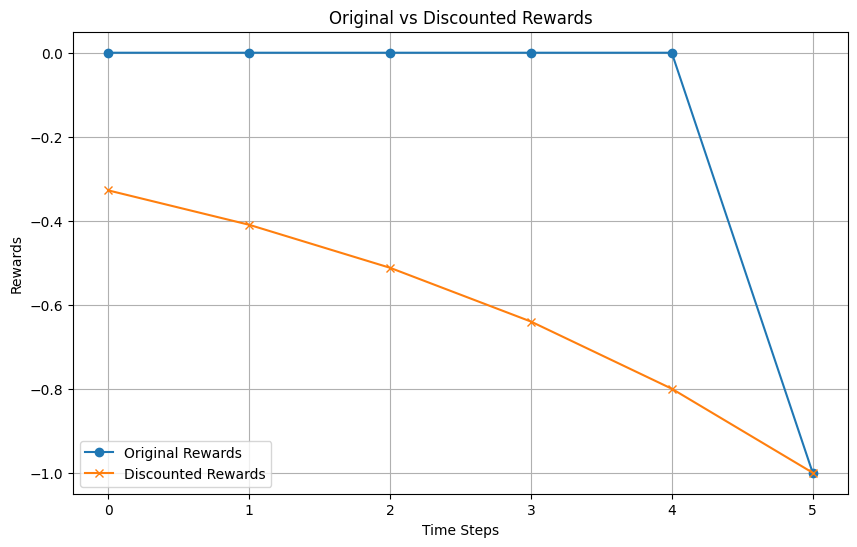

In [ ]:
# Discount rewards function
def dis_rewards(rewards, gamma):
    discounted = np.zeros_like(rewards, dtype=np.float32)
    running_add = 0
    for t in reversed(range(len(rewards))):
        if rewards[t] != 0:  # Reset at game boundary
            running_add = 0
        running_add = running_add * gamma + rewards[t]
        discounted[t] = running_add
    return discounted

# Example rewards data
rewards = [0, 0, -1, 0, -1, 0, 0, -1, 0, 0, 0, 0, -1, 0, 0]
rewards = [0, 0, 0, 0, 0, 1]
rewards = [0, 0, 0, 0, 0, -1]
gamma = 0.8

# Calculate discounted rewards
dis_rewards = dis_rewards(rewards, gamma)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(rewards, label="Original Rewards", marker='o')
plt.plot(dis_rewards, label="Discounted Rewards", marker='x')
plt.title("Original vs Discounted Rewards")
plt.xlabel("Time Steps")
plt.ylabel("Rewards")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Hyperparameters
H = 200  # Number of hidden layer neurons
batch_size = 10  # Number of episodes before parameter update
learning_rate = 1e-4
gamma = 0.99  # Discount factor for reward
render = True  # Render the environment

# Initialize the network and optimizer
D = 80 * 80  # Input dimensionality: 80x80 grid
policy_net = PolicyNetwork(D, H, 1)
optimizer = optim.RMSprop(policy_net.parameters(), lr=learning_rate, alpha=0.99)

# Preprocessing function
def prepro(frame):
    """Preprocess 210x160x3 uint8 frame into 6400 (80x80) 1D float vector"""
    frame = frame[35:195]  # Crop
    frame = frame[::2, ::2, 0]  # Downsample by factor of 2
    frame[(frame == 144) | (frame == 109)] = 0  # Erase background
    frame[frame != 0] = 1  # Set paddles and ball to 1
    return frame.astype(np.float32).ravel()

# Main program
env = gym.make("ale_py:ALE/Pong-v5", render_mode="rgb_array")
env = PassiveEnvChecker(env)  # Add PassiveEnvChecker wrapper
env = OrderEnforcing(env, disable_render_order_enforcing=False)  # Add OrderEnforcing wrapper

observation, info = env.reset()
prev_x = None
xs, rewards, actions = [], [], []
running_reward = None
reward_sum = 0
episode_number = 0

while True:
    if render:
        env.render()

    # Preprocess observation
    cur_x = prepro(observation)
    x = cur_x - prev_x if prev_x is not None else np.zeros(D)
    prev_x = cur_x
    x = torch.tensor(x, dtype=torch.float32)

    # Forward pass to get action probability
    aprob = policy_net(x).item()
    action = 2 if np.random.uniform() < aprob else 3

    # Record intermediates
    xs.append(x)
    actions.append(1 if action == 2 else 0)

    # Step the environment
    observation, reward, terminated, truncated, info = env.step(action)
    reward_sum += reward
    rewards.append(reward)

    if terminated or truncated:
        episode_number += 1

        # Stack episode data
        epx = torch.stack(xs)
        epa = torch.tensor(actions, dtype=torch.float32)
        epr = torch.tensor(discount_rewards(rewards, gamma), dtype=torch.float32)

        # Normalize rewards
        epr = (epr - epr.mean()) / (epr.std() + 1e-5)

        # Compute loss
        probs = policy_net(epx).squeeze()
        loss = -(torch.log(probs) * epa * epr).mean()

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Reset episode memory
        xs, rewards, actions = [], [], []

        # Bookkeeping
        running_reward = reward_sum if running_reward is None else running_reward * 0.99 + reward_sum * 0.01
        print(f'Episode {episode_number} finished. Total reward: {reward_sum}. Running mean: {running_reward}')
        reward_sum = 0
        observation, info = env.reset()
        prev_x = None

        if episode_number % 100 == 0:
            print("Saving model...")
            torch.save(policy_net.state_dict(), "policy_net.pth")

    if reward != 0:  # Pong has +1 or -1 reward at game end
        print(f'Episode {episode_number}: game finished, reward: {reward:.2f}')


Episode 0: game finished, reward: 1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 0: game finished, reward: -1.00
Episode 1 finished. Total reward: -20.0. Running mean: -20.0
Episode 1: game finished, reward: -1.00
Episode 1: game finished, reward: -1.00
Episode 1: game fini

KeyboardInterrupt: 